# Linear Regression – House Price Prediction
Features: `area_sqft`, `bedrooms`, `age_years`, `distance_to_city_km`  
Target: `price_lakhs`

## 1. Load the data

In [1]:
# Import the libraries we need for data handling, plotting and modelling.
# pandas = tables, matplotlib/seaborn = graphs, sklearn = machine learning.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

# Read the CSV file into a DataFrame (a table).
# Show the first 5 rows to understand what the data looks like.
df = pd.read_csv("house_prices.csv")
df.head()

,area_sqft,bedrooms,age_years,distance_to_city_km,price_lakhs
0,678,2,10,19.7,23.50
1,2047,3,24,24.3,73.95
2,1809,3,0,13.0,98.65
3,1377,3,26,4.5,73.18
4,1366,1,16,1.3,80.08


## 2. Easy EDA

In [2]:
# Check the size of the data, column types and missing values.
# info() shows types, isnull().sum() counts missing values per column.
print("Shape:", df.shape)
df.info()
print("\nMissing values:\n", df.isnull().sum())

Shape: (100, 5)
<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   area_sqft            100 non-null    int64  
 1   bedrooms             100 non-null    int64  
 2   age_years            100 non-null    int64  
 3   distance_to_city_km  100 non-null    float64
 4   price_lakhs          100 non-null    float64
dtypes: float64(2), int64(3)
memory usage: 4.0 KB

Missing values:
 area_sqft              0
bedrooms               0
age_years              0
distance_to_city_km    0
price_lakhs            0
dtype: int64


In [3]:
# describe() gives quick statistics: mean, min, max, spread for each column.
# This helps us see the range of each feature (they are on very different scales).
df.describe()

,area_sqft,bedrooms,age_years,distance_to_city_km,price_lakhs
count,100.000000,100.000000,100.00000,100.000000,100.000000
mean,1552.960000,2.490000,14.19000,12.329000,75.419500
std,545.663676,1.087068,9.32109,7.357773,32.442112
min,587.000000,1.000000,0.00000,1.300000,2.930000
25%,1144.250000,2.000000,6.00000,4.925000,52.687500
50%,1539.000000,2.000000,13.00000,12.450000,77.565000
75%,2025.250000,3.000000,23.00000,19.700000,97.000000
max,2451.000000,5.000000,29.00000,24.500000,149.110000


## 3. Two simple graphs

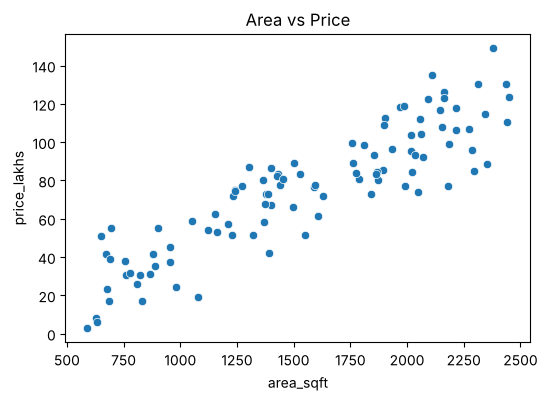

In [4]:
# Graph 1: Scatter plot of the most important feature (area) vs price.
# If the dots form a rising line, a linear model is a good fit.
plt.figure(figsize=(6,4))
sns.scatterplot(x="area_sqft", y="price_lakhs", data=df)
plt.title("Area vs Price")
plt.show()

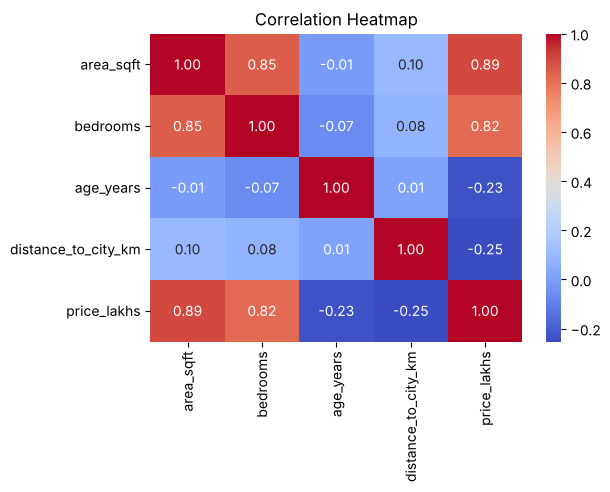

In [5]:
# Graph 2: Correlation heatmap shows how strongly each column is related to others.
# Values near +1 or -1 = strong relation, near 0 = weak relation.
plt.figure(figsize=(6,4))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

## 4. Split features (X) and target (y)

In [6]:
# X = input columns (features) the model learns from.
# y = the column we want to predict (price).
X = df.drop("price_lakhs", axis=1)
y = df["price_lakhs"]
print("Features:", list(X.columns))

Features: ['area_sqft', 'bedrooms', 'age_years', 'distance_to_city_km']


## 5. Train / Test split

In [7]:
# Split data: 80% for training the model, 20% for testing it on unseen data.
# random_state=42 makes the split the same every time we run it.
# We split BEFORE scaling so the test data does not leak into the scaler.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train size:", X_train.shape, " Test size:", X_test.shape)

Train size: (80, 4)  Test size: (20, 4)


## 6. Standard Scaling
StandardScaler converts each feature to mean = 0 and std = 1, so area (500–2500) does not dominate bedrooms (1–5).

In [8]:
# Create the scaler, learn mean/std from TRAIN data only (fit),
# then apply the same transformation to both train and test data (transform).
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Show the scaled training data as a table to confirm mean ~ 0 and std ~ 1.
pd.DataFrame(X_train_scaled, columns=X.columns).describe().loc[["mean","std"]].round(2)

,area_sqft,bedrooms,age_years,distance_to_city_km
mean,-0.00,0.00,0.00,0.00
std,1.01,1.01,1.01,1.01


## 7. Train the model

In [9]:
# Create the Linear Regression model and train it using the scaled training data.
# fit() finds the best coefficients (weights) for each feature.
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Show the learned weights: bigger absolute value = more influence on price.
coef = pd.DataFrame({"feature": X.columns, "coefficient": model.coef_})
print("Intercept:", round(model.intercept_, 2))
coef

Intercept: 76.27


,feature,coefficient
0,area_sqft,24.962101
1,bedrooms,5.565067
2,age_years,-6.811961
3,distance_to_city_km,-10.814149


## 8. Predict & evaluate

In [10]:
# Use the trained model to predict prices for the unseen test data.
# Then compare predictions with real values using R2 (closer to 1 = better) and RMSE (lower = better).
y_pred = model.predict(X_test_scaled)
print("R2 score:", round(r2_score(y_test, y_pred), 3))
print("RMSE    :", round(mean_squared_error(y_test, y_pred) ** 0.5, 2))

R2 score: 0.981
RMSE    : 5.26


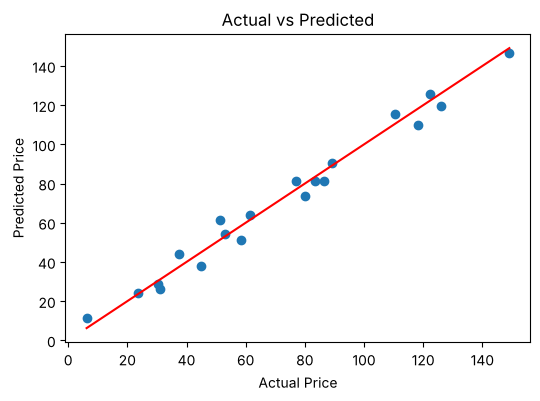

In [11]:
# Plot actual vs predicted prices. Points close to the red line = good predictions.
plt.figure(figsize=(6,4))
plt.scatter(y_test, y_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Price"); plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted")
plt.show()

## 9. Give your own input, get the output

In [12]:
# Put a new house's details in a DataFrame (same column order as training).
# IMPORTANT: scale it with the SAME scaler before predicting.
new_house = pd.DataFrame({
    "area_sqft": [1200],
    "bedrooms": [2],
    "age_years": [5],
    "distance_to_city_km": [8.0]
})
new_scaled = scaler.transform(new_house)

# Predict and print the result.
predicted_price = model.predict(new_scaled)
print(f"Predicted price: {predicted_price[0]:.2f} lakhs")

Predicted price: 69.31 lakhs


## 10. Ridge Regression
Ridge adds an **L2 penalty** to Linear Regression: it punishes large coefficients, so they shrink towards zero (but never become exactly zero).  
`alpha` controls the strength: bigger alpha = more shrinking. It helps when features are correlated or the model overfits.

In [ ]:
from sklearn.linear_model import Ridge

# Create the Ridge model and train it on the same scaled training data.
# alpha=10 is the penalty strength (alpha=0 would be the same as plain Linear Regression).
ridge = Ridge(alpha=10)
ridge.fit(X_train_scaled, y_train)

# Predict on the unseen test data and measure the score, just like before.
ridge_pred = ridge.predict(X_test_scaled)
print("Ridge R2 score:", round(r2_score(y_test, ridge_pred), 3))
print("Ridge RMSE    :", round(mean_squared_error(y_test, ridge_pred) ** 0.5, 2))

# Compare Ridge coefficients with plain Linear Regression: Ridge values are slightly smaller.
pd.DataFrame({
    "feature": X.columns,
    "linear_coef": model.coef_,
    "ridge_coef": ridge.coef_
}).round(3)

## 11. Lasso Regression
Lasso adds an **L1 penalty**: it can push the coefficients of weak features **exactly to zero**, so it also works as automatic feature selection.  
Again `alpha` controls the strength: bigger alpha = more features get removed.

In [ ]:
from sklearn.linear_model import Lasso

# Create the Lasso model and train it on the same scaled training data.
# alpha=1 is the penalty strength.
lasso = Lasso(alpha=1)
lasso.fit(X_train_scaled, y_train)

# Predict on the unseen test data and measure the score.
lasso_pred = lasso.predict(X_test_scaled)
print("Lasso R2 score:", round(r2_score(y_test, lasso_pred), 3))
print("Lasso RMSE    :", round(mean_squared_error(y_test, lasso_pred) ** 0.5, 2))

# Compare Lasso coefficients with plain Linear Regression.
# A coefficient of 0.0 means Lasso decided that feature is not useful.
pd.DataFrame({
    "feature": X.columns,
    "linear_coef": model.coef_,
    "lasso_coef": lasso.coef_
}).round(3)